<a href="https://colab.research.google.com/github/scrayzk/solar-energy-prediction/blob/main/solar_energy_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Solar Energy Production Prediction (CS 316 – Phase 2)
Predicts solar power output from weather measurements using **pandas, numpy, seaborn and scikit-learn**.

## 1. Imports
seaborn draws the charts (matplotlib is installed with it and only used to show them). scikit-learn provides the models and metrics.

In [1]:
#import training models and libraries required for data structuring, data cleaning, visualization.
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style(style="whitegrid")

## 2. Get the data from GitHub
This downloads the repo, including the data/ folder, into Colab.

In [2]:
!git clone https://github.com/scrayzk/solar-energy-prediction.git
%cd solar-energy-prediction

Cloning into 'solar-energy-prediction'...
remote: Enumerating objects: 48, done.
remote: Counting objects: 100% (48/48), done.
remote: Compressing objects: 100% (42/42), done.
remote: Total 48 (delta 14), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (48/48), 2.34 MiB | 5.81 MiB/s, done.
Resolving deltas: 100% (14/14), done.
/content/solar-energy-prediction


## 3. Load the data
Each plant has a **generation** file (power from 22 inverters every 15 min) and a **weather** file (one sensor per plant).
Plant 1's generation file writes dates as day-month-year, so we tell pandas the format. The other files use the standard format.

In [3]:
# Load solar power generation data and weather sensor data for both plants
gen1 = pd.read_csv("data/Plant_1_Generation_Data.csv")
gen2 = pd.read_csv("data/Plant_2_Generation_Data.csv")
w1 = pd.read_csv("data/Plant_1_Weather_Sensor_Data.csv")
w2 = pd.read_csv("data/Plant_2_Weather_Sensor_Data.csv")

# Convert the DATE_TIME column in gen1 to datetime format using its specific string format
gen1["DATE_TIME"] = pd.to_datetime(gen1["DATE_TIME"], format="%d-%m-%Y %H:%M")

# Convert the DATE_TIME column to datetime format for the remaining datasets using automatic parsing
for df in (gen2, w1, w2):
    df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"])

gen1.head()

,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,2020-05-15,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,2020-05-15,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,2020-05-15,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


<Axes: xlabel='AC_POWER', ylabel='Count'>

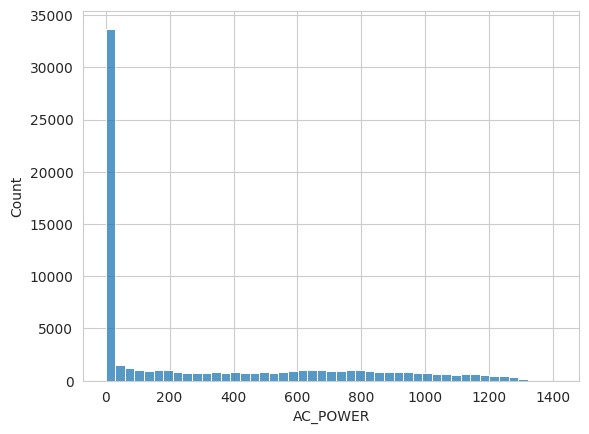

In [33]:
sns.histplot(gen1["AC_POWER"])

## 4. Clean and merge (Task: data collection and cleaning)
1. Stack the two plants together.
2. Check for missing values and duplicates, and remove them.
3. The generation file has many inverters per timestamp, so we take the **average AC power per inverter** for each plant and timestamp. This matches the plant-level weather readings (one row per timestamp).
4. Merge generation and weather on `DATE_TIME` + `PLANT_ID`.

In [5]:
# Combine generation amd weather data from both plants into a single dataframe
gen = pd.concat([gen1, gen2], ignore_index=True) # Reset the index
weather = pd.concat([w1, w2], ignore_index=True)

# Print the number of missing values in each column
print("Missing values in generation data:\n", gen.isna().sum(), "\n")
print("Missing values in weather data:\n", weather.isna().sum(), "\n")

# One row per plant per timestamp: average AC power across inverters
power = gen.groupby(["DATE_TIME", "PLANT_ID"], as_index=False)["AC_POWER"].mean()

# Merge with weather (inner join keeps only timestamps that exist in both)
weather = weather[["DATE_TIME", "PLANT_ID", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]]
data = power.merge(weather, on=["DATE_TIME", "PLANT_ID"], how="inner")

print("Merged dataset shape:", data.shape)
data.head()

Missing values in generation data:
 DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64 

Missing values in weather data:
 DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64 

Merged dataset shape: (6416, 6)


,DATE_TIME,PLANT_ID,AC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,0.0,25.184316,22.857507,0.0
1,2020-05-15 00:00:00,4136001,0.0,27.004764,25.060789,0.0
2,2020-05-15 00:15:00,4135001,0.0,25.084589,22.761668,0.0
3,2020-05-15 00:15:00,4136001,0.0,26.880811,24.421869,0.0
4,2020-05-15 00:30:00,4135001,0.0,24.935753,22.592306,0.0


In [6]:
print("Plant-timestamps in generation data:", len(power))
print("Weather rows:", len(weather))
print("After merge: ", len(data))

Plant-timestamps in generation data: 6417
Weather rows: 6441
After merge:  6416


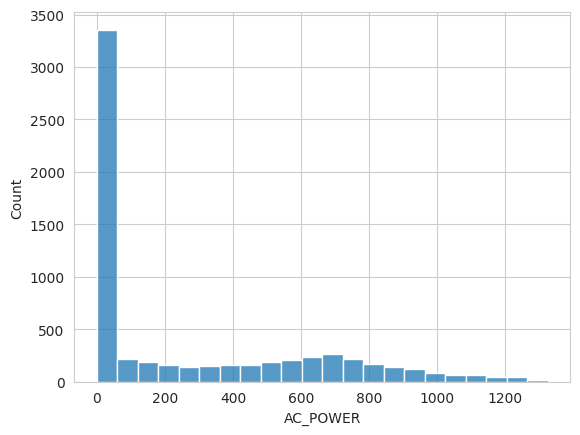

In [7]:
sns.histplot(data["AC_POWER"])
plt.show()

## 5. Feature engineering
New columns that help the models:
- `PLANT`: 1 or 2 (plants behave a little differently).
- `HOUR`: time of day as a number (e.g. 13.5 = 1:30 pm). Solar output follows the sun.
- `TEMP_DIFF`: module temperature minus ambient temperature.

At night the panels produce nothing and irradiation is 0, which is trivially easy to predict and would inflate our scores.
So we keep **daytime rows only** (`IRRADIATION > 0`).

In [8]:
data["PLANT"] = data["PLANT_ID"].map({4135001: 1, 4136001: 2}) # Map the raw plant IDs to readable plant numbers (1 and 2)
data["HOUR"] = data["DATE_TIME"].dt.hour + data["DATE_TIME"].dt.minute / 60 # Extract the hour of the day
data["TEMP_DIFF"] = data["MODULE_TEMPERATURE"] - data["AMBIENT_TEMPERATURE"] # Calculate the temperature difference

# Filter out zero-sunlight data points where irradiation is 0 or less
data = data[data["IRRADIATION"] > 0].reset_index(drop=True)

# Select features and target
features = ["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "TEMP_DIFF", "HOUR", "PLANT"]
target = "AC_POWER"

data[features + [target]].describe().round(2)

,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,TEMP_DIFF,HOUR,PLANT,AC_POWER
count,3616.00,3616.00,3616.00,3616.00,3616.00,3616.00,3616.00
mean,0.41,28.71,39.05,10.35,12.28,1.51,485.47
std,0.31,3.90,11.38,8.87,3.95,0.50,342.03
min,0.00,20.40,18.24,-3.76,0.00,1.00,0.00
25%,0.12,25.74,29.09,2.02,9.00,1.00,162.84
50%,0.39,28.36,38.70,9.57,12.25,2.00,498.88
75%,0.67,31.55,48.55,17.68,15.56,2.00,740.12
max,1.22,39.18,66.64,35.24,23.75,2.00,1325.01


In [9]:
data.shape

(3616, 9)

## 6. Exploratory data analysis
Three charts: how strongly each variable relates to power (heatmap), power vs. irradiation, and the daily power curve.

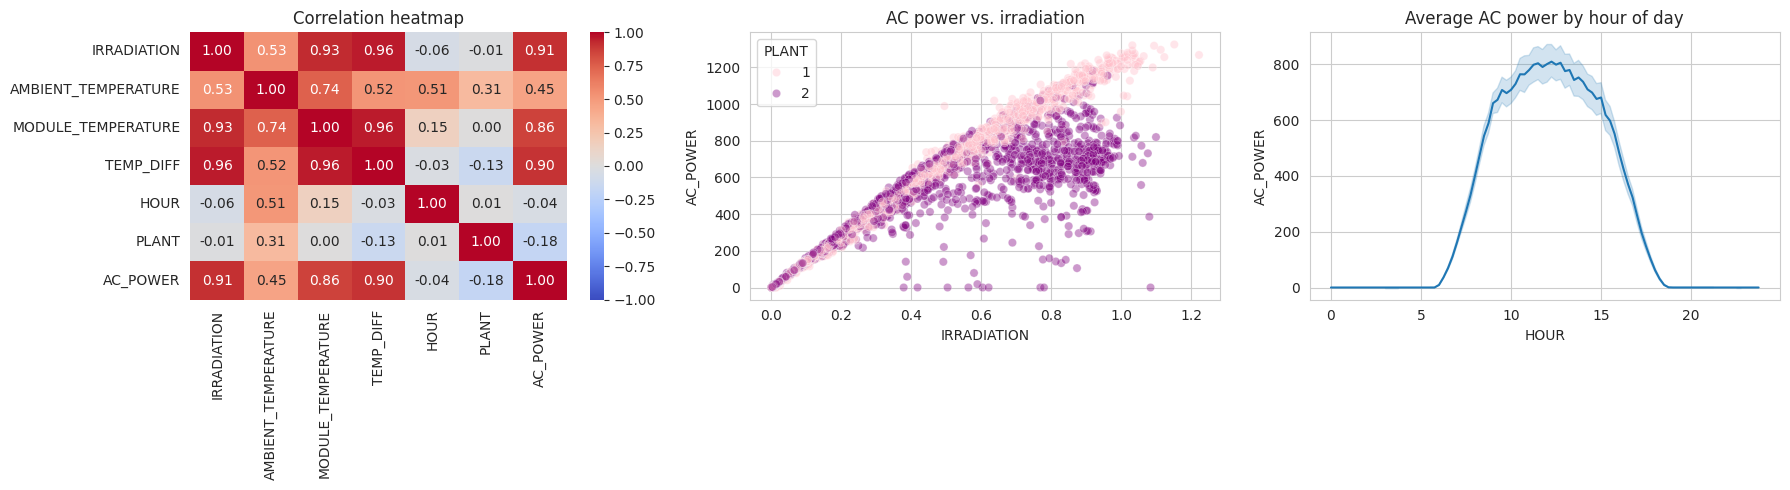

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#Chart 1: correlation heatmap, +1 = rise together, 0 = no linear relationship, -1 = one rises as the other falls
sns.heatmap(data[features + [target]].corr(), annot=True, fmt=".2f", cmap="coolwarm",center=0,vmin=-1,vmax=1, ax=axes[0])
axes[0].set_title("Correlation heatmap")

# Chart 2: scatter plot of AC power against irradiation, coloured by plant
sns.scatterplot(data=data, x="IRRADIATION", y="AC_POWER", hue="PLANT",palette={1: "pink", 2: "purple"}, alpha=0.4, ax=axes[1])
axes[1].set_title("AC power vs. irradiation")

# Chart 3: average AC power at each time of day
# Seaborn averages AC_POWER over all days and plants at each HOUR value and draws the line;
# the shaded band is the 95% confidence interval of that average
sns.lineplot(data=data, x="HOUR", y="AC_POWER", ax=axes[2])
axes[2].set_title("Average AC power by hour of day")

plt.tight_layout()
plt.show()

## 7. Train / test split
Weather data is a time series, so a random split would "leak" neighbouring 15-minute rows into both sets.
Instead we train on the **first 80% of days** and test on the **last 20%**. This tests how well the model predicts days it has never seen.

In [11]:
# Get all unique days in chronological order
days = np.sort(data["DATE_TIME"].dt.normalize().unique())

# Use the first 80% of days for training
cutoff = days[int(len(days) * 0.8)]

# Split data by complete days
train = data[data["DATE_TIME"] < cutoff]
test = data[data["DATE_TIME"] >= cutoff]

# Separate features and target
X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

print(f"Train: {len(train)} rows | Test: {len(test)} rows | Test starts on {str(cutoff)[:10]}")

Train: 2862 rows | Test: 754 rows | Test starts on 2020-06-11


## 8. Train and compare the models (Task: model development + evaluation)
We train 3 regression models and score each on the unseen test days with:
- **MAE**: average error in kW (easy to read).
- **RMSE**: like MAE but punishes big misses more.
- **R²**: share of the variation in power the model explains (1.0 is perfect).

In [12]:
# Define a dictionary of machine learning models to train and evaluate
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
}

rows, predictions = [], {}

# Iterate through each model, train it, generate predictions, and evaluate performance
for name, model in models.items():
    # Fit the model on the training data
    model.fit(X_train, y_train)

    # Predict on test set
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

'''after calculating mse, rmse, mae the output is shown in the form of dataframe.
the output is sorted by the rmse values going from lowest to highest.'''
results = pd.DataFrame(rows).set_index("Model").sort_values("RMSE").round(3)
results

,MAE,RMSE,R2
Model,,,
Random Forest,35.135,77.949,0.935
Decision Tree,37.530,85.441,0.922
Linear Regression,97.960,125.807,0.831


## 9. Visualise the results
Left: RMSE per model (lower is better). Middle: predicted vs. actual power for the best model (points on the red line are perfect predictions). Right: correlation of each feature with AC power. The further a bar is from zero, the stronger the relationship. A positive bar means power rises as the feature rises, and a negative bar means it falls.

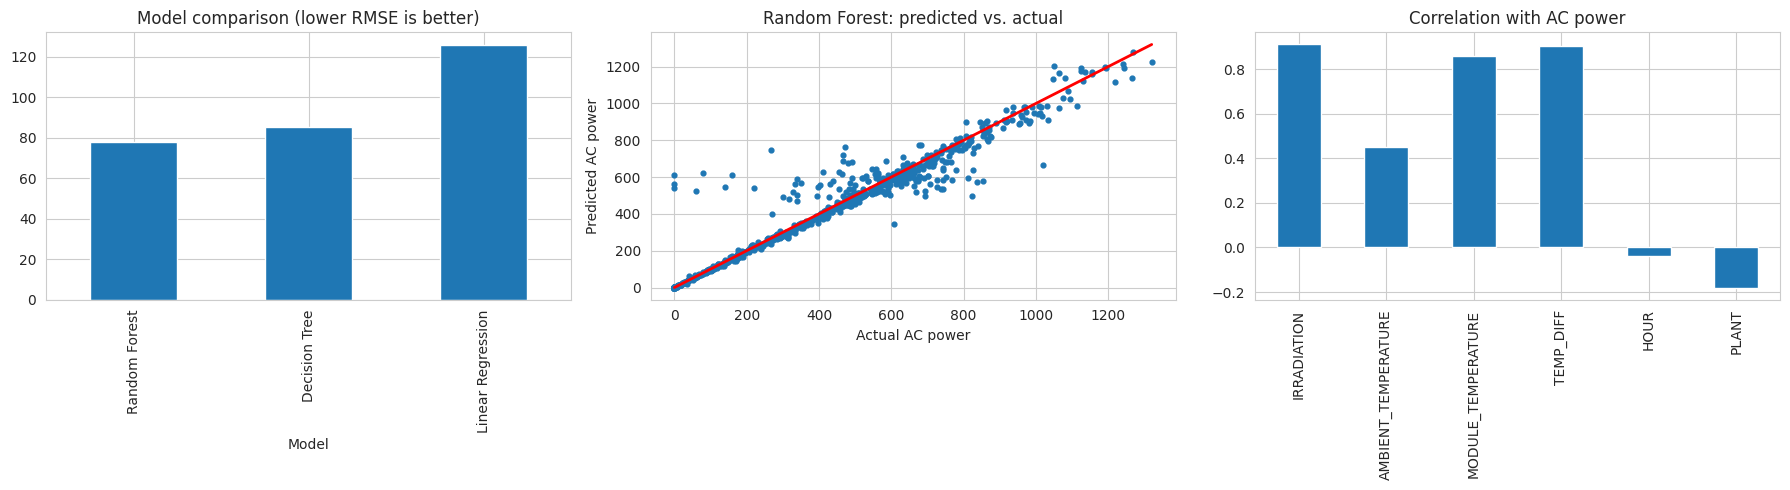

In [23]:
#since the dataframe containing the 3 metrics(mae,mse,rmse) have been sorted by lowest rmse, we choose the first index which is random forest.
best_name = results.index[0]
best_model = models[best_name]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#bar plot depicting the root mean squared error. (the lower the value, the better)
results["RMSE"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Model comparison (lower RMSE is better)")

#scatter plot depicting predicted vs. actual ac_power.
#the red line is the ideal prediction, points closer to the line indicate good prediction.
axes[1].scatter(y_test, predictions[best_name],s=12)
axes[1].plot([0, y_test.max()], [0, y_test.max()], color="red", linewidth = 2)
axes[1].set_xlabel("Actual AC power")
axes[1].set_ylabel("Predicted AC power")
axes[1].set_title(f"{best_name}: predicted vs. actual")

#bar plot depicting correlation between AC power and different features. (IRRADIATION has the strongest relationship with solar power prediction.)
corrs= data[features + [target]].corr()[target].drop(target)

'''the above line takes 7 columns from the data table and correlates it against
the target column i.e. AC_power. since the selected 7 columns also includes the target column,
we drop it when correlating since ac_power against itself will give a value of 1.(doesnt highlight anything)'''

corrs.plot(kind="bar", ax=axes[2])
axes[2].set_title("Correlation with AC power")

plt.tight_layout()
plt.show()

## 10. Fill in the summary
This prints the project summary with the blanks from your abstract filled in automatically.

In [14]:
#summary of the notebook including methods, observations and results
best = results.loc[best_name]
top_feature = corrs.abs().idxmax()

print(
    "Solar power output fluctuates with weather conditions, complicating grid planning and increasing "+"\n"+
    "reliance on fossil-fuel backup generation. This project builds a supervised regression pipeline that "+"\n"+
    "predicts solar power generation from weather measurements, using 34 days of 15-minute interval data "+"\n"+
    "from two grid-connected solar plants in India. Generation and weather records were merged, cleaned, "+"\n"+
    f"and enriched with engineered features, then used to train and compare {len(models)} regression models "+"\n"+
    f"evaluated with MAE, RMSE, and R². The best-performing model was {best_name} "+"\n"+
    f"(MAE = {best['MAE']:.2f} kW, RMSE = {best['RMSE']:.2f} kW, R² = {best['R2']:.3f}), "+"\n"+
    f"and the main driver of solar output was {top_feature}. The results illustrate how better forecasting "+"\n"+
    "can support renewable-energy integration and reduce dependence on backup fossil-fuel generation."+"\n"
)

Solar power output fluctuates with weather conditions, complicating grid planning and increasing 
reliance on fossil-fuel backup generation. This project builds a supervised regression pipeline that 
predicts solar power generation from weather measurements, using 34 days of 15-minute interval data 
from two grid-connected solar plants in India. Generation and weather records were merged, cleaned, 
and enriched with engineered features, then used to train and compare 3 regression models 
evaluated with MAE, RMSE, and R². The best-performing model was Random Forest 
(MAE = 35.13 kW, RMSE = 77.95 kW, R² = 0.935), 
and the main driver of solar output was IRRADIATION. The results illustrate how better forecasting 
can support renewable-energy integration and reduce dependence on backup fossil-fuel generation.

